# Settings Comparison — Overview

Loads parsed ProteoBench output and provides:
1. An analysis overview: which search engines, settings, and datasets were included
2. Benchmark scatter figures showing precursor count vs. quantification error
   across all tools, instruments, and setting configurations

The ProteoBench output can be either created from the original search results stored on PRIDE (See notebook `01_parse_results.ipynb`) or the processed output can be directly loaded from [Zenodo](https://doi.org/10.5281/zenodo.21181080) at ./Data/ProteoBench

## 1. Imports & load data

In [16]:
import os
import pickle

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from SCI_py.constants.plotting import SOFTWARE_COLORS, LAB_COLORS, LAB_ORDER
from SCI_py.plot.settings_comparison import (
    filter_recommended,
    apply_version_filter,
    plot_scatter_all_tools,
    plot_scatter_per_tool,
    plot_scatter_instrument_split,
    plot_scatter_tool_instrument_grid,
    plot_scatter_recommended,
    plot_scatter_recommended_split,
    plot_scatter_averaged,
)

In [17]:
ZENODO_FOLDER = '/public/conode53/sam/SCI_paper/Zenodo'
FIGURE_PATH = '/home/sam/SCI/SCI/Figures/Figure_2/overview'

DATA_PATH   = os.path.join(ZENODO_FOLDER, 'Data', 'ProteoBench')
with open(os.path.join(DATA_PATH, 'datapoints.pkl'), 'rb') as f:
    datapoints = pickle.load(f)

with open(os.path.join(DATA_PATH, 'intermediates.pkl'), 'rb') as f:
    intermediates = pickle.load(f)

print(f'{len(datapoints)} datapoints  |  {len(intermediates):,} intermediate rows')

75 datapoints  |  1,020,110 intermediate rows


## 2. Analysis overview

In [ ]:
engines = sorted(datapoints['search_engine'].unique())
labs    = sorted(datapoints['lab'].unique())

print(f'Search engines  ({len(engines)}): {" | ".join(engines)}')
print(f'Labs / datasets ({len(labs)}): {" | ".join(labs)}')
print(f'Total datapoints: {len(datapoints)}')
print()

for engine in engines:
    settings = sorted(datapoints.loc[datapoints['search_engine'] == engine, 'comments'].unique())
    print(f'{engine}  ({len(settings)} configurations):')
    for s in settings:
        print(f'  • {s}')

Search engines  (6): AlphaDIA | CHIMERYS | DIA-NN | MSFragger | PEAKS | Spectronaut
Labs / datasets (9): Astral_1 | Astral_2 | Astral_3 | Astral_4 | Astral_5 | Astral_6 | timsTOF_1 | timsTOF_2 | timsTOF_3
Total datapoints: 75

AlphaDIA  (1 configurations):
  • Default
CHIMERYS  (2 configurations):
  • 5.0.0 MS2(Area)
  • 5.0.0 MS2(Area) TIC-norm
DIA-NN  (2 configurations):
  • DIANN 2.6
  • DIANN 2.6 (1st pass)
MSFragger  (1 configurations):
  • standard
PEAKS  (2 configurations):
  • MBR
  • MBR TIC-norm
Spectronaut  (1 configurations):
  • DirectDIA+ method-evaluation


### Count matrix
Number of setting configurations run per search engine per lab.


In [19]:
count_table = (
    datapoints
    .groupby(['search_engine', 'lab'])
    .size()
    .unstack('lab', fill_value=0)
)
count_table.insert(0, 'Total', count_table.sum(axis=1))

display(
    count_table.style
    .background_gradient(cmap='Blues', subset=count_table.columns[1:])
    .set_caption('Settings configurations per search engine and lab (0 = not run)')
    .format(na_rep='—')
)


lab,Total,Astral_1,Astral_2,Astral_3,Astral_4,Astral_5,Astral_6,timsTOF_1,timsTOF_2,timsTOF_3
search_engine,,,,,,,,,,
AlphaDIA,9,1,1,1,1,1,1,1,1,1
CHIMERYS,16,2,2,2,2,2,0,2,2,2
DIA-NN,18,2,2,2,2,2,2,2,2,2
MSFragger,8,1,1,1,1,1,0,1,1,1
PEAKS,16,2,2,2,2,2,0,2,2,2
Spectronaut,8,1,1,1,1,1,0,1,1,1


### Setting names per engine
Which configuration names are defined for each engine across all labs.


In [20]:
rows = []
for engine in engines:
    sub      = datapoints[datapoints['search_engine'] == engine]
    n_labs_e = sub['lab'].nunique()
    for comment in sorted(sub['comments'].unique()):
        n_labs_c = sub.loc[sub['comments'] == comment, 'lab'].nunique()
        rows.append({'search_engine': engine, 'configuration': comment,
                     'labs_with_this_setting': n_labs_c})

settings_detail = pd.DataFrame(rows)

display(
    settings_detail.style
    .set_caption('All configuration names and how many labs ran each one')
    .bar(subset=['labs_with_this_setting'], color='#a8d8a8')
    .hide(axis='index')
)


search_engine,configuration,labs_with_this_setting
AlphaDIA,Default,9
CHIMERYS,5.0.0 MS2(Area),8
CHIMERYS,5.0.0 MS2(Area) TIC-norm,8
DIA-NN,DIANN 2.6,9
DIA-NN,DIANN 2.6 (1st pass),9
MSFragger,standard,8
PEAKS,MBR,8
PEAKS,MBR TIC-norm,8
Spectronaut,DirectDIA+ method-evaluation,8


### Trusted runs

Edit `ALLOWED_RUNS` to keep only the `(software_name, comment)` combinations you trust.
Comment out or remove any row you want to exclude from all figures below.
All subsequent analysis cells apply this filter automatically.


In [21]:
ALLOWED_RUNS = {
    'AlphaDIA': [
        'Default',
    ],
    'DIA-NN': [
        'DIANN 2.6',
        'DIANN 2.6 (1st pass)',
        'Default (1st pass)',
        'Default (2nd pass)',
        # 'Library-free',
        # 'Library-free (recommended settings)',
        # 'MBR',
    ],
    'FragPipe (DIA-NN quant)': [
        'standard',
    ],
    'MSAID': [
        '4.4.1 MS2(Area)',
        '4.4.1 MS2(Area) TIC-norm',
        '5.0.0 MS1(Area)',
        '5.0.0 MS1(Area) TIC-norm',
        '5.0.0 MS1(Area)-MBR',
        '5.0.0 MS1(Area)-MBR TIC-norm',
        '5.0.0 MS2(Area)',
        '5.0.0 MS2(Area) TIC-norm',
    ],
    'PEAKS': [
        'MBR',
        'MBR TIC-norm',
        'MaxLFQ / MBR / TIC-norm',
        'Optimized isolation settings / MaxLFQ',
        'Optimized isolation settings / MaxLFQ TIC-norm',
        'Recommended',
        'Recommended TIC-norm',
    ],
    'Spectronaut': [
        # 'DirectDIA+', (peptide length to 52 allowed)
        'DirectDIA+ method-evaluation',
        'Library',
        'Library (Astral + timsTOF)',
        'The real method-evaluation',
        'The real method-evaluation TIC-norm',
    ],
}


def _apply_allowed_runs(df, allowed=ALLOWED_RUNS):
    """Keep only rows whose (software_name, comments) pair is in ALLOWED_RUNS."""
    mask = df.apply(
        lambda r: r['comments'] in allowed.get(r['software_name'], []),
        axis=1
    )
    return df[mask]


datapoints = _apply_allowed_runs(datapoints)
print(f'{len(datapoints)} datapoints after applying ALLOWED_RUNS.')


75 datapoints after applying ALLOWED_RUNS.


##34. Benchmark scatter figures

Axes: x = mean absolute quantification error (ε), y = number of identified precursors.
Upper-left is best (more identifications, lower error).


### 3.1 All tools — all datasets
Each point is one (tool, lab, settings) combination. Colour = search engine.

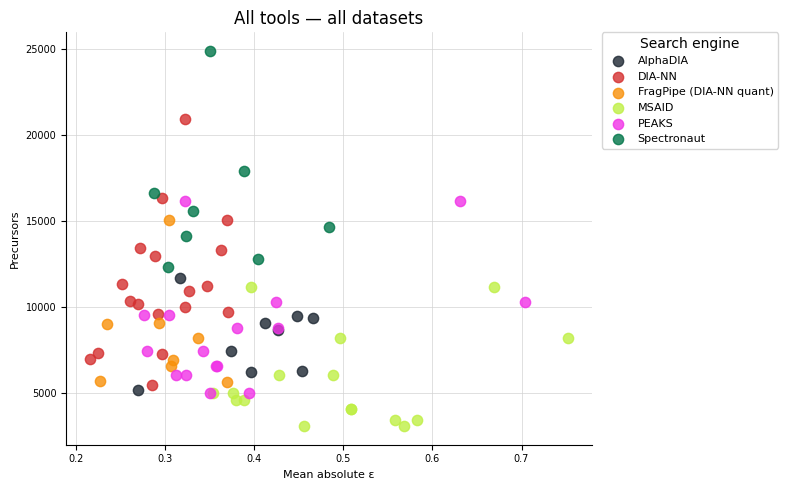

In [23]:
plot_scatter_all_tools(
    datapoints,
    color_map = SOFTWARE_COLORS,
    save_dir  = FIGURE_PATH,
    show      = True,
)

### 3.2 Per-tool panels — colour by lab
One subplot per search engine; all setting configurations shown. Colour = lab.

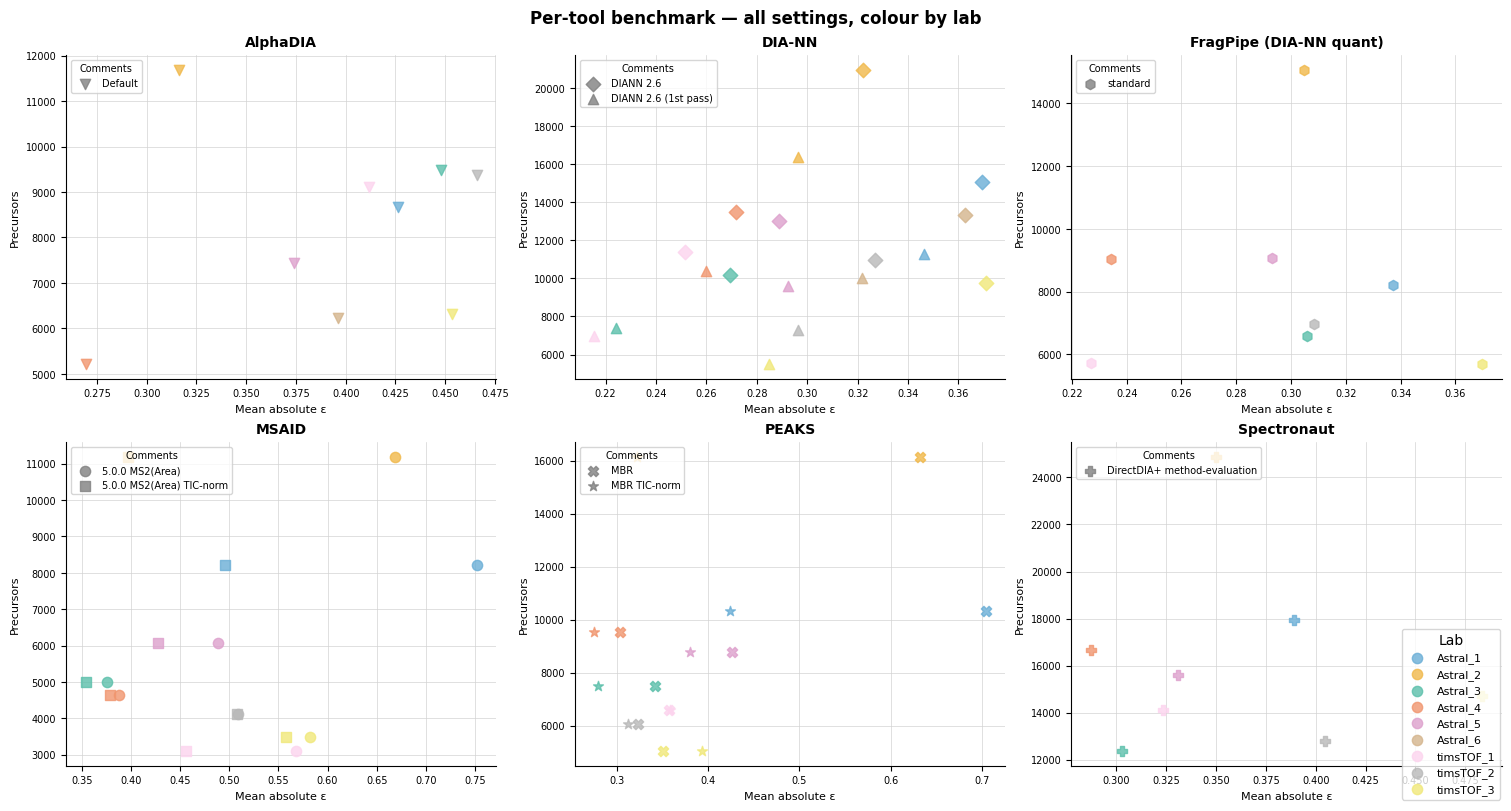

In [24]:
plot_scatter_per_tool(
    datapoints,
    lab_colors = LAB_COLORS,
    lab_order  = LAB_ORDER,
    save_dir   = FIGURE_PATH,
    show       = True,
)

### 3.3 Astral vs timsTOF — all settings
Left panel: Astral labs. Right panel: timsTOF labs. Colour = search engine.

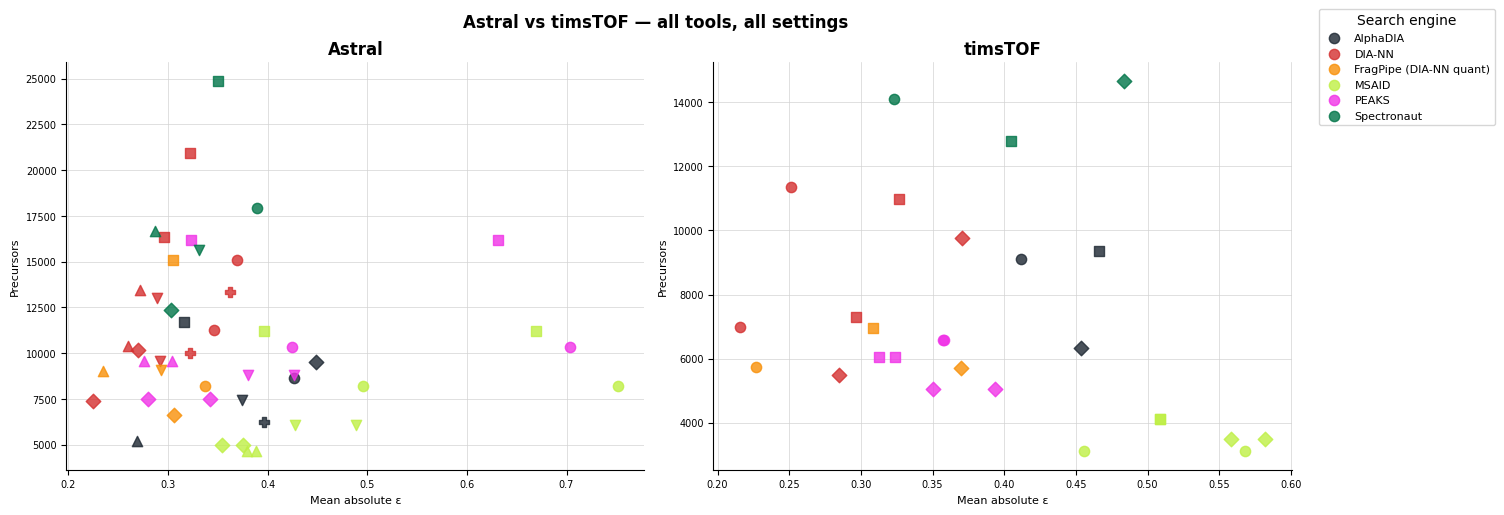

In [25]:
plot_scatter_instrument_split(
    datapoints,
    color_map = SOFTWARE_COLORS,
    save_dir  = FIGURE_PATH,
    show      = True,
)

### 3.4 Per-tool × instrument-type panels
Rows = search engines. Left column = Astral, right column = timsTOF. Colour = lab.

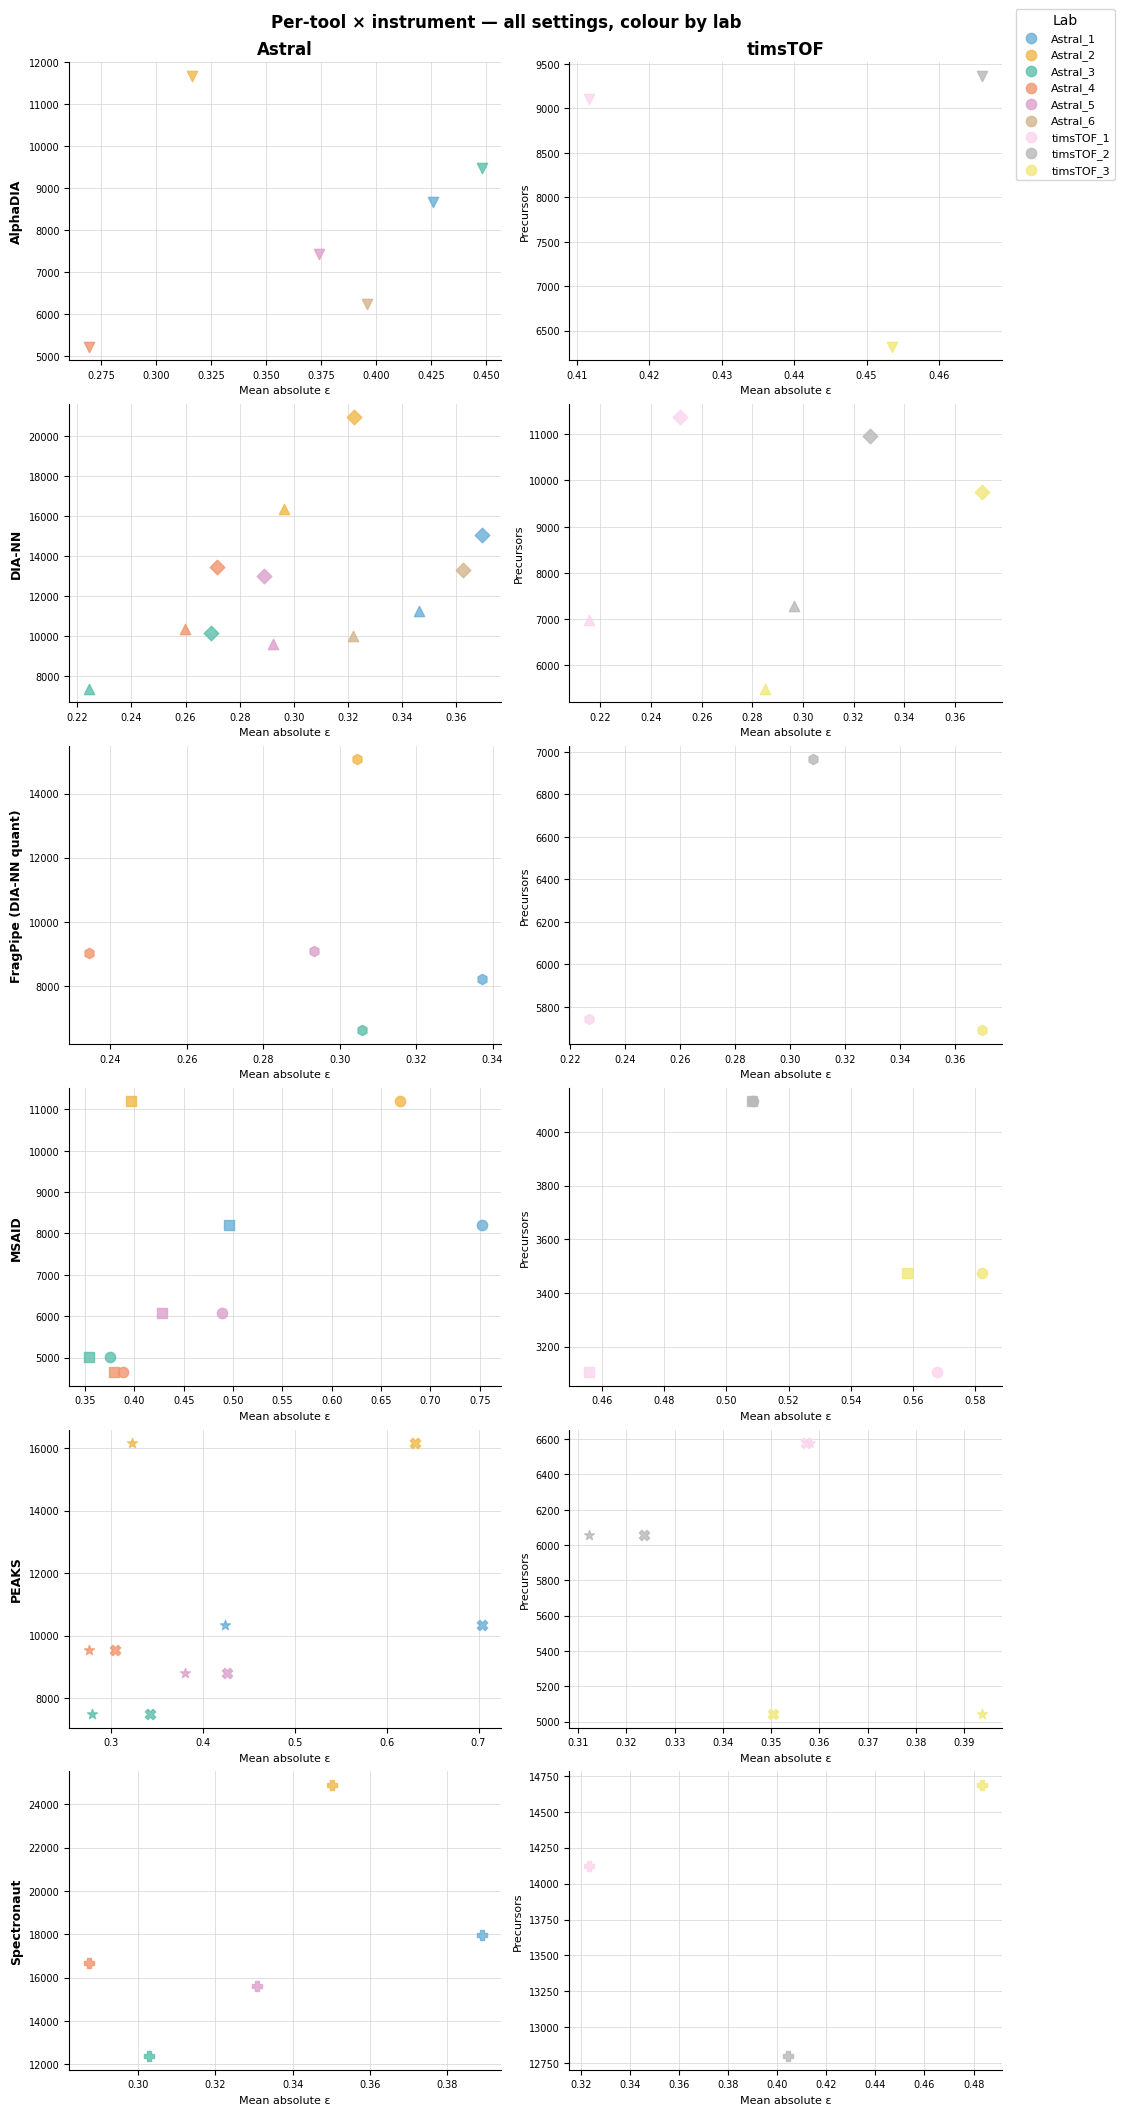

In [26]:
plot_scatter_tool_instrument_grid(
    datapoints,
    lab_colors = LAB_COLORS,
    lab_order  = LAB_ORDER,
    save_dir   = FIGURE_PATH,
    show       = True,
)

### 3.5 Recommended settings only

Two panels: left = no-MBR recommended setting per tool, right = MBR setting per tool.
Colour = search engine.

> Edit `recommended_settings` and `recommended_settings_mbr` below to change the selection.


### Version and best-settings selection

Configure `version_filter` and `best_settings_averaged` here before running the figures.
The discovery cell prints what is available in the loaded data.


In [27]:
# Available software versions per search engine present in datapoints.
# Use these values in version_filter below.
for engine in sorted(datapoints['software_name'].unique()):
    vers = (
        datapoints.loc[datapoints['software_name'] == engine, 'comments']
        .dropna()
        .str.strip()
        .unique()
    )
    print(f'{engine}: {sorted(vers)}')


AlphaDIA: ['Default']
DIA-NN: ['DIANN 2.6', 'DIANN 2.6 (1st pass)']
FragPipe (DIA-NN quant): ['standard']
MSAID: ['5.0.0 MS2(Area)', '5.0.0 MS2(Area) TIC-norm']
PEAKS: ['MBR', 'MBR TIC-norm']
Spectronaut: ['DirectDIA+ method-evaluation']


In [29]:
# Restrict each search engine to one software version.
# Set to None to accept all versions for that engine.
# Values are matched after stripping whitespace.
version_filter = {
    'AlphaDIA':    '2.0.1',
    'MSAID':    None,
    'DIA-NN':      '2.6.0 Academia',   # or '2.6.0 Academia' for the DIANN 2.6 run
    'FragPipe (DIA-NN quant)':   '24.0',
    'PEAKS':       None,
    'Spectronaut': '20.3.251119.92449',
}

# Best configuration per engine for the instrument-averaged figure (section 4.7).
# Keys are search_engine values; values must match the 'comments' column exactly.
best_settings_averaged = {
    'AlphaDIA':    'Default',
    'MSAID':    '5.0.0 MS2(Area) TIC-norm',
    'DIA-NN':      'DIANN 2.6',
    'FragPipe (DIA-NN quant)':   'standard',
    'PEAKS':       'MBR TIC-norm',
    'Spectronaut': 'DirectDIA+ method-evaluation',
}

# Keys are values of the `search_engine` column in datapoints.
recommended_settings = {
    'AlphaDIA':              'Default',
    'MSAID':              '5.0.0 MS2(Area) TIC-norm',
    'DIA-NN':                'DIANN 2.6 (1st pass)',
    'FragPipe (DIA-NN quant)':             'standard',
    'PEAKS':                 'Recommended TIC-norm',
    'Spectronaut':           'DirectDIA+ method-evaluation',
}

recommended_settings_mbr = {
    'AlphaDIA':              'Default',
    'MSAID':              '5.0.0 MS2(Area) TIC-norm',
    'DIA-NN':                'DIANN 2.6',
    'FragPipe (DIA-NN quant)':             'standard',
    'PEAKS':                 'MBR TIC-norm',
    'Spectronaut':           'DirectDIA+ method-evaluation',
}

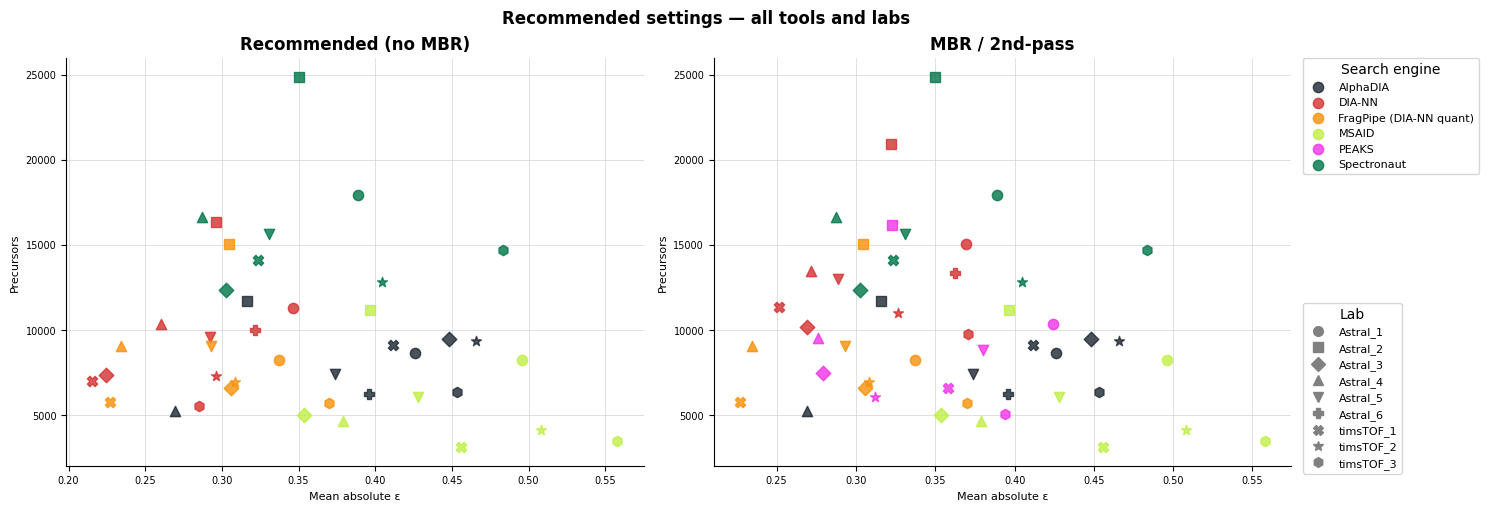

Recommended (no MBR): 42 points
MBR / 2nd-pass:       50 points


In [30]:
plot_scatter_recommended(
    datapoints,
    recommended     = recommended_settings,
    recommended_mbr = recommended_settings_mbr,
    color_map       = SOFTWARE_COLORS,
    lab_order       = LAB_ORDER,
    save_dir        = FIGURE_PATH,
    show            = True,
)

### 3.6 Recommended settings — Astral vs timsTOF
Same filter as 4.5, split by instrument type.

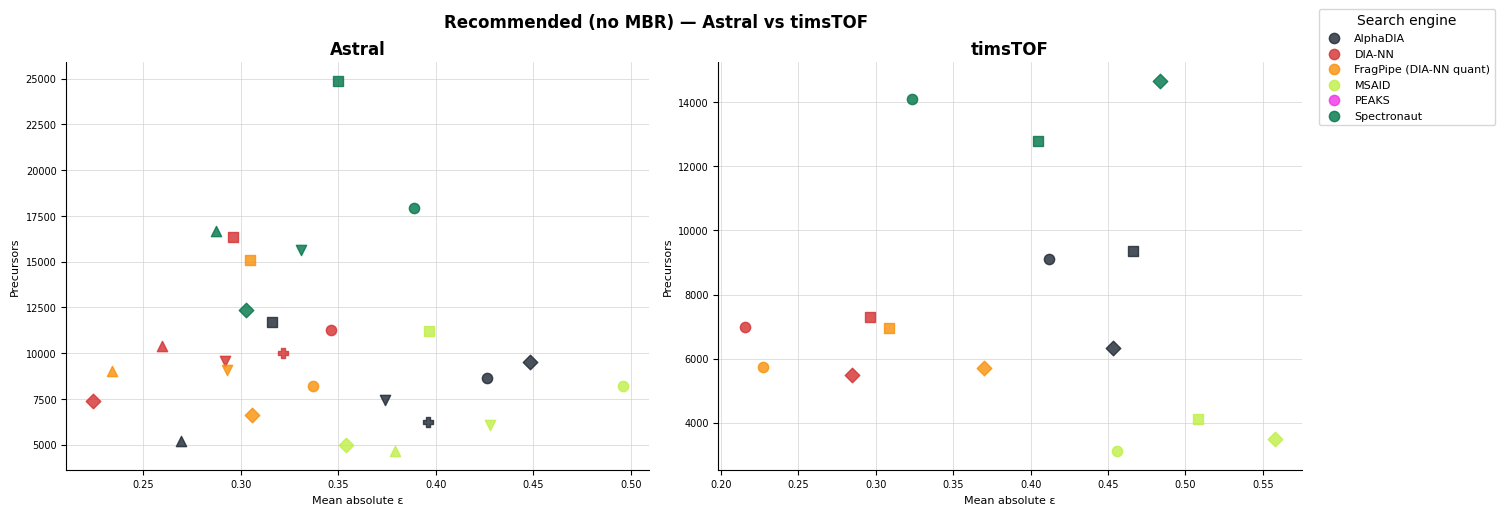

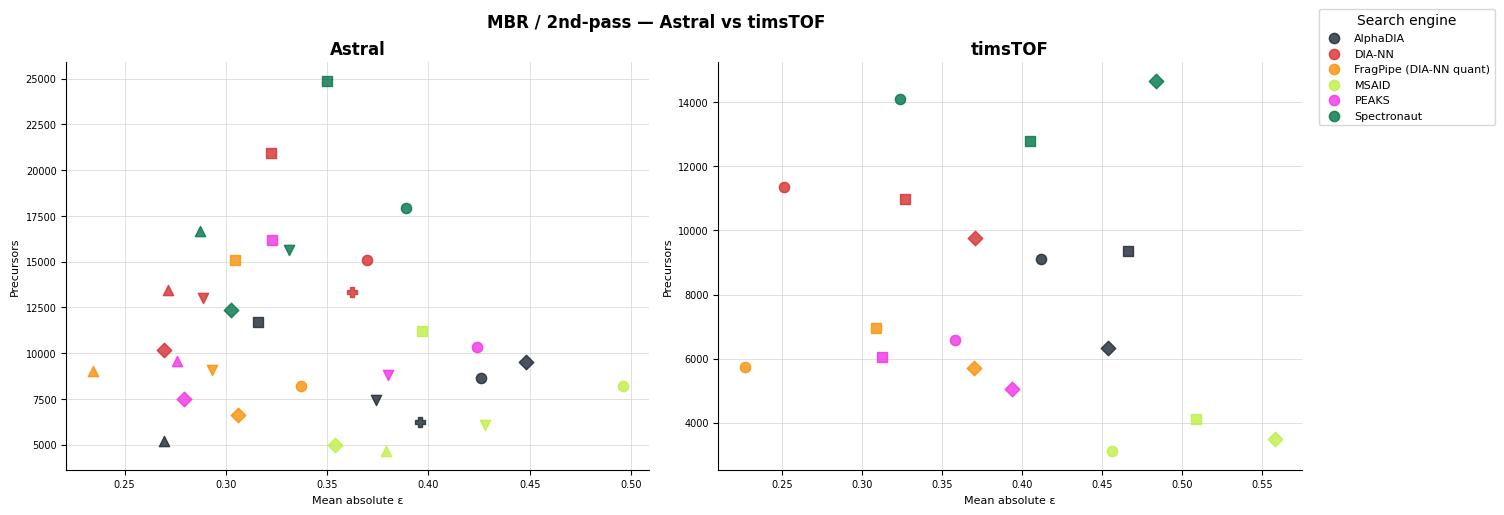

In [31]:
plot_scatter_recommended_split(
    datapoints,
    recommended     = recommended_settings,
    recommended_mbr = recommended_settings_mbr,
    color_map       = SOFTWARE_COLORS,
    save_dir        = FIGURE_PATH,
    show            = True,
)

### 3.7 Instrument-averaged performance

One dot per *(search engine, instrument type)* combination.  
Metrics are the mean across all labs of that instrument type.  
Applies `version_filter` and `best_settings_averaged` from the selection cell above.  
Colour = search engine · Shape = instrument type (● Astral, ■ timsTOF).


In [32]:
dtps_versioned = apply_version_filter(datapoints, version_filter)
dtps_best_avg  = filter_recommended(dtps_versioned, best_settings_averaged)

dtps_best_avg = dtps_best_avg.copy()
dtps_best_avg['instrument_type'] = dtps_best_avg['lab'].apply(
    lambda x: 'Astral' if 'Astral' in x else 'timsTOF'
)

averaged = (
    dtps_best_avg
    .groupby(['software_name', 'instrument_type'])
    .agg(
        mean_abs_epsilon=('mean_abs_epsilon', 'mean'),
        nr_prec         =('nr_prec',          'mean'),
        n_labs          =('lab',               'count'),
    )
    .reset_index()
)

print(averaged[['software_name', 'instrument_type',
                'mean_abs_epsilon', 'nr_prec', 'n_labs']].to_string(index=False))

          software_name instrument_type mean_abs_epsilon       nr_prec  n_labs
               AlphaDIA          Astral         0.371595        8119.0       6
               AlphaDIA         timsTOF         0.443733        8266.0       3
                 DIA-NN          Astral         0.313989  14329.333333       6
                 DIA-NN         timsTOF          0.31635  10695.666667       3
FragPipe (DIA-NN quant)          Astral         0.295026        9597.4       5
FragPipe (DIA-NN quant)         timsTOF         0.301709   6130.666667       3
                  MSAID          Astral         0.410654        7024.4       5
                  MSAID         timsTOF         0.507404   3564.666667       3
                  PEAKS          Astral         0.336375       10460.0       5
                  PEAKS         timsTOF         0.354651   5891.333333       3
            Spectronaut          Astral         0.331999       17492.6       5
            Spectronaut         timsTOF         0.40

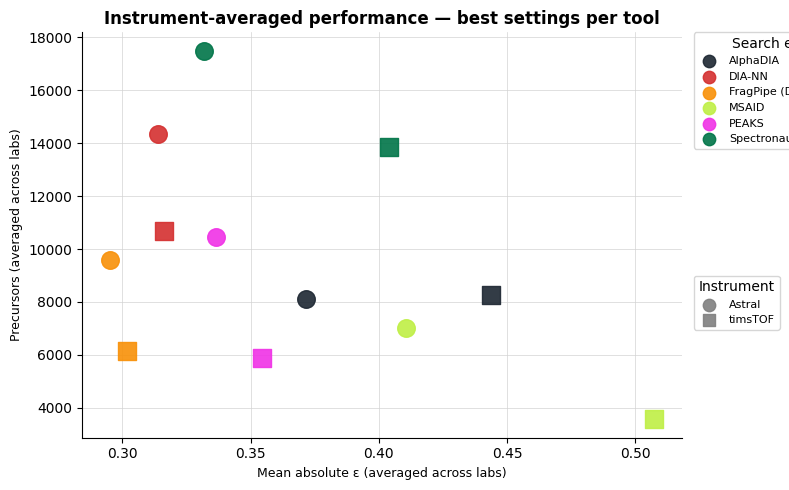

In [37]:
plot_scatter_averaged(
    averaged,
    color_map = SOFTWARE_COLORS,
    save_dir  = FIGURE_PATH,
    show      = True,
)

## 4. Statistics

In [38]:
dtps_best_avg

,id,software_name,software_version,search_engine,search_engine_version,ident_fdr_psm,ident_fdr_peptide,ident_fdr_protein,enable_match_between_runs,precursor_mass_tolerance,...,intermediate_hash,results,median_abs_epsilon,mean_abs_epsilon,nr_prec,comments,proteobench_version,plate_id,lab,instrument_type
0,AlphaDIA_20260704_132222,AlphaDIA,2.0.1,AlphaDIA,None,0.01,None,0.01,True,"[-15.0 ppm, 15.0 ppm]",...,4a5499a15dd2ed51884bbf01b1ecfd40e3ac73d9,"{11: {'median_abs_epsilon': nan, 'mean_abs_eps...",0.316695,0.453547,6319,Default,/,BYU_timsTOF_1,timsTOF_3,timsTOF
2,MSAID_20260704_132226,MSAID,,CHIMERYS,5.0.0,0.01,0.01,0.01,False,None,...,f213ca2a610a952c781b4eba1fb76dac8ead657a,"{11: {'median_abs_epsilon': nan, 'mean_abs_eps...",0.314925,0.557972,3476,5.0.0 MS2(Area) TIC-norm,/,BYU_timsTOF_1,timsTOF_3,timsTOF
3,DIA-NN_20260704_132232,DIA-NN,2.6.0 Academia,DIA-NN,2.6.0 Academia,None,None,None,True,"[-15.0 ppm, 15.0 ppm]",...,c684eb1a4ddf9a8d3cd3ddada3d2cf77b648523f,"{11: {'median_abs_epsilon': nan, 'mean_abs_eps...",0.218729,0.370773,9753,DIANN 2.6,/,BYU_timsTOF_1,timsTOF_3,timsTOF
5,FragPipe (DIA-NN quant)_20260704_132307,FragPipe (DIA-NN quant),24.0,MSFragger,4.4.1,0.01,,0.01,False,"[-10 ppm, 10 ppm]",...,97280621ad4948106e10cf92672f4df5d732f727,"{11: {'median_abs_epsilon': nan, 'mean_abs_eps...",0.20558,0.369742,5688,standard,/,BYU_timsTOF_1,timsTOF_3,timsTOF
7,PEAKS_20260704_132314,PEAKS,,PEAKS,,,,,False,Auto Detected,...,25c6245a38f924f3d9779b7758bf012c88c057ac,"{11: {'median_abs_epsilon': nan, 'mean_abs_eps...",0.28538,0.393677,5041,MBR TIC-norm,/,BYU_timsTOF_1,timsTOF_3,timsTOF
8,Spectronaut_20260704_132322,Spectronaut,20.3.251119.92449,Spectronaut,20.3.251119.92449,0.01,,0.01,False,Dynamic,...,cb1b6daae594c7212663d8c936da2d60e2026c78,"{11: {'median_abs_epsilon': nan, 'mean_abs_eps...",0.318481,0.483444,14686,DirectDIA+ method-evaluation,/,BYU_timsTOF_1,timsTOF_3,timsTOF
9,AlphaDIA_20260704_132326,AlphaDIA,2.0.1,AlphaDIA,None,0.01,None,0.01,True,"[-15.0 ppm, 15.0 ppm]",...,3ff833eaf95564fdfafed4a6a0939b3b80b4a374,"{11: {'median_abs_epsilon': nan, 'mean_abs_eps...",0.356886,0.46593,9369,Default,/,Broad_timsTOF_1,timsTOF_2,timsTOF
11,MSAID_20260704_132331,MSAID,,CHIMERYS,5.0.0,0.01,0.01,0.01,False,None,...,375f2676eb7baab44a9ec5265f15b1885298489f,"{11: {'median_abs_epsilon': nan, 'mean_abs_eps...",0.363985,0.508348,4114,5.0.0 MS2(Area) TIC-norm,/,Broad_timsTOF_1,timsTOF_2,timsTOF
12,DIA-NN_20260704_132338,DIA-NN,2.6.0 Academia,DIA-NN,2.6.0 Academia,None,None,None,True,"[-15.0 ppm, 15.0 ppm]",...,3a61681a934a99990dd87822e4b10b2cbc580c12,"{11: {'median_abs_epsilon': nan, 'mean_abs_eps...",0.229615,0.326695,10970,DIANN 2.6,/,Broad_timsTOF_1,timsTOF_2,timsTOF
14,FragPipe (DIA-NN quant)_20260704_132412,FragPipe (DIA-NN quant),24.0,MSFragger,4.4.1,0.01,,0.01,False,"[-10 ppm, 10 ppm]",...,3c9a7a145767381e3723da489051229cf118d50f,"{11: {'median_abs_epsilon': nan, 'mean_abs_eps...",0.211465,0.308445,6964,standard,/,Broad_timsTOF_1,timsTOF_2,timsTOF


In [39]:
# Group by software name and lab (not instrument_type), then calculate statistics for nr_prec
nr_prec_by_lab = (
    dtps_best_avg
    .groupby(['software_name', 'lab'])
    .agg(
        mean_nr_prec=('nr_prec', 'mean'),
        median_nr_prec=('nr_prec', 'median'),
        min_nr_prec=('nr_prec', 'min'),
        max_nr_prec=('nr_prec', 'max'),
        count=('nr_prec', 'count'),
    )
    .reset_index()
    .sort_values(['software_name', 'lab'])
)

display(
    nr_prec_by_lab.style
    .set_caption('Number of precursors (nr_prec) overview by software and lab')
    .format({
        'mean_nr_prec': '{:.0f}',
        'median_nr_prec': '{:.0f}',
        'min_nr_prec': '{:.0f}',
        'max_nr_prec': '{:.0f}',
    })
    .hide(axis='index')
)

software_name,lab,mean_nr_prec,median_nr_prec,min_nr_prec,max_nr_prec,count
AlphaDIA,Astral_1,8663,8663,8663,8663,1
AlphaDIA,Astral_2,11688,11688,11688,11688,1
AlphaDIA,Astral_3,9492,9492,9492,9492,1
AlphaDIA,Astral_4,5215,5215,5215,5215,1
AlphaDIA,Astral_5,7432,7432,7432,7432,1
AlphaDIA,Astral_6,6224,6224,6224,6224,1
AlphaDIA,timsTOF_1,9110,9110,9110,9110,1
AlphaDIA,timsTOF_2,9369,9369,9369,9369,1
AlphaDIA,timsTOF_3,6319,6319,6319,6319,1
DIA-NN,Astral_1,15071,15071,15071,15071,1


In [40]:
nr_prec_by_lab[
    nr_prec_by_lab.apply(lambda row: 'tims' in row['lab'], axis=1)
].sort_values('mean_nr_prec')

,software_name,lab,mean_nr_prec,median_nr_prec,min_nr_prec,max_nr_prec,count
31,MSAID,timsTOF_1,3104.0,3104.0,3104,3104,1
33,MSAID,timsTOF_3,3476.0,3476.0,3476,3476,1
32,MSAID,timsTOF_2,4114.0,4114.0,4114,4114,1
41,PEAKS,timsTOF_3,5041.0,5041.0,5041,5041,1
25,FragPipe (DIA-NN quant),timsTOF_3,5688.0,5688.0,5688,5688,1
23,FragPipe (DIA-NN quant),timsTOF_1,5740.0,5740.0,5740,5740,1
40,PEAKS,timsTOF_2,6056.0,6056.0,6056,6056,1
8,AlphaDIA,timsTOF_3,6319.0,6319.0,6319,6319,1
39,PEAKS,timsTOF_1,6577.0,6577.0,6577,6577,1
24,FragPipe (DIA-NN quant),timsTOF_2,6964.0,6964.0,6964,6964,1
